# UCS420 Lab Assignment 9 — NLP Text Preprocessing
**Name:** Aayush  
**Roll number:** 1024170351  
**Dataset fingerprint:** `6FC07742`  

Run the notebook from top to bottom. The instructor-provided dataset generator and official `process_ticket()` function are preserved unchanged.

In [1]:
ROLL_NO = 1024170351          # <-- your full roll number
NAME = "Aayush"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170351   Name: Aayush   Fingerprint: 6FC07742   Tickets: 13

Ticket_ID                                                                     Ticket_Text
      T01                               The password failed to open. It worked yesterday.
      T02                              The lms keeps asking for login. Please resolve it.
      T03                                 The lms stopped responding. Can you check this?
      T04      Password is running slowly after restarting the system. Please resolve it.
      T05                                           The Wi-Fi works, but the VPN doesn't.
      T06 I cannot access the VPN after the latest update. The same problem occurs again.
      T07                              The projector is showing an error. This is urgent.
      T08                                                  Error code 0x80070005 appears.
      T09                 The laptop was working yesterday. It works on another computer.
      T10             

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Your code
from IPython.display import display
import pandas as pd

# Process every ticket using the original function
processed = {}
rows = []

for row in df.itertuples(index=False):
    result = process_ticket(row.Ticket_Text)
    processed[row.Ticket_ID] = result

    rows.append({
        "Ticket ID": row.Ticket_ID,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

q1_table = pd.DataFrame(rows)

# Total row: total counts and corpus-wide unique vocabulary
total_row = {
    "Ticket ID": "TOTAL",
    "Sentences": q1_table["Sentences"].sum(),
    "Tokens": q1_table["Tokens"].sum(),
    "Punctuation tokens": q1_table["Punctuation tokens"].sum(),
    "Stopwords": q1_table["Stopwords"].sum(),
    "Unique tokens": len({
        token
        for result in processed.values()
        for token in result["tokens"]
    }),
    "Final tokens": q1_table["Final tokens"].sum()
}

q1_table = pd.concat(
    [q1_table, pd.DataFrame([total_row])],
    ignore_index=True
)

display(q1_table)

# Display actual token lists for one selected ticket
selected_id = FOCUS[0]
selected = processed[selected_id]

selected_text = df.loc[
    df["Ticket_ID"] == selected_id, "Ticket_Text"
].iloc[0]

print("\nSelected ticket:", selected_id)
print("Raw text:", selected_text)
print("Actual tokens:", selected["tokens"])
print("Punctuation tokens:", selected["punct"])
print("Stopwords:", selected["stops"])
print("Final tokens:", selected["final"])

# Observation: contraction fragments that remain in final tokens
fragments = {
    "n't", "'s", "'re", "'ve", "'d", "'ll",
    "'m", "ca", "wo"
}

found_fragments = sorted({
    token
    for result in processed.values()
    for token in result["final"]
    if token in fragments
})

print("\nNon-standard-looking final tokens:", found_fragments)
print("These usually originate from contractions split by word_tokenize().")

,Ticket ID,Sentences,Tokens,Punctuation tokens,Stopwords,Unique tokens,Final tokens
0,T01,2,10,2,3,9,5
1,T02,2,11,2,3,10,6
2,T03,2,10,2,4,10,4
3,T04,2,13,2,4,12,7
4,T05,1,10,2,4,9,4
5,T06,2,17,2,9,14,6
6,T07,2,11,2,5,9,4
7,T08,1,5,1,0,5,4
8,T09,2,12,2,4,11,6
9,T10,2,12,2,5,12,5



Selected ticket: T03
Raw text: The lms stopped responding. Can you check this?
Actual tokens: ['the', 'lms', 'stopped', 'responding', '.', 'can', 'you', 'check', 'this', '?']
Punctuation tokens: ['.', '?']
Stopwords: ['the', 'can', 'you', 'this']
Final tokens: ['lms', 'stopped', 'responding', 'check']

Non-standard-looking final tokens: ["n't"]
These usually originate from contractions split by word_tokenize().


**Observation — non-word final tokens:** The final tokens include `n't`, which is not normally a standalone word. For example, `doesn't` is split by `word_tokenize()` into `does` and `n't`. The word `does` is removed as a stopword, but `n't` is not in NLTK’s English stopword list, so it remains in the final tokens. Such fragments come from contraction tokenization.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re
from IPython.display import display

def regex_extract(text):
    return {
        "Words longer than 5 letters": re.findall(
            r"\b[A-Za-z]{6,}\b", text
        ),

        # Preserves 95.5, 2.0.1, 1,250 and hexadecimal error codes
        "Numbers": re.findall(
            r"(?<!\w)(?:0[xX][0-9A-Fa-f]+|\d+(?:[.,]\d+)*)(?!\w)",
            text
        ),

        "Capitalized words": re.findall(
            r"\b[A-Z][A-Za-z]*\b", text
        ),

        "Words beginning with a vowel": re.findall(
            r"\b[AEIOU][A-Za-z]*\b",
            text,
            flags=re.IGNORECASE
        )
    }


EMAIL_PATTERN = (
    r"\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b"
)

URL_PATTERN = r"\b(?:https?://|www\.)[^\s<>\"']+"

PHONE_PATTERN = (
    r"(?<!\w)(?:\+\d{1,3}[\s-]?)?"
    r"(?:\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})(?!\w)"
)


def replace_sensitive(text):
    # Replace email addresses
    text = re.sub(
        EMAIL_PATTERN, "<EMAIL>", text, flags=re.IGNORECASE
    )

    # Avoid consuming sentence punctuation after URLs
    def replace_url(match):
        original = match.group(0)
        url = original.rstrip(".,;:!?)]}")
        return "<URL>" + original[len(url):]

    text = re.sub(
        URL_PATTERN, replace_url, text, flags=re.IGNORECASE
    )

    # Replace phone numbers
    text = re.sub(PHONE_PATTERN, "<PHONE>", text)

    return text


# Extract and replace data in every generated ticket
ticket_regex_results = []

for row in df.itertuples(index=False):
    result = regex_extract(row.Ticket_Text)
    result["Ticket ID"] = row.Ticket_ID
    result["After replacement"] = replace_sensitive(row.Ticket_Text)
    ticket_regex_results.append(result)

print("REGEX RESULTS ON GENERATED TICKETS")
display(pd.DataFrame(ticket_regex_results))


# Validate the patterns against the provided TEST_LINES
test_regex_results = []

for i, line in enumerate(TEST_LINES, start=1):
    result = regex_extract(line)
    result["Test line"] = i
    result["After replacement"] = replace_sensitive(line)
    test_regex_results.append(result)

print("\nREGEX RESULTS ON TEST_LINES")
display(pd.DataFrame(test_regex_results))


# Count capitalized words occurring at sentence beginnings.
# These are candidates for capitalization caused by sentence position.
initial_words = []

for text in df["Ticket_Text"]:
    for sentence in sent_tokenize(text):
        match = re.search(r"[A-Za-z]+", sentence)
        if match and match.group(0)[0].isupper():
            initial_words.append(match.group(0))

print(
    "\nCapitalized sentence-initial word occurrences:",
    len(initial_words)
)
print("Examples:", initial_words[:20])

REGEX RESULTS ON GENERATED TICKETS


,Words longer than 5 letters,Numbers,Capitalized words,Words beginning with a vowel,Ticket ID,After replacement
0,"[password, failed, worked, yesterday]",[],"[The, It]","[open, It]",T01,The password failed to open. It worked yesterday.
1,"[asking, Please, resolve]",[],"[The, Please]","[asking, it]",T02,The lms keeps asking for login. Please resolve...
2,"[stopped, responding]",[],"[The, Can]",[],T03,The lms stopped responding. Can you check this?
3,"[Password, running, slowly, restarting, system...",[],"[Password, Please]","[is, after, it]",T04,Password is running slowly after restarting th...
4,[],[],"[The, Wi, Fi, VPN]",[],T05,"The Wi-Fi works, but the VPN doesn't."
5,"[cannot, access, latest, update, problem, occurs]",[],"[I, VPN, The]","[I, access, after, update, occurs, again]",T06,I cannot access the VPN after the latest updat...
6,"[projector, showing, urgent]",[],"[The, This]","[is, an, error, is, urgent]",T07,The projector is showing an error. This is urg...
7,[appears],[0x80070005],[Error],"[Error, appears]",T08,Error code 0x80070005 appears.
8,"[laptop, working, yesterday, another, computer]",[],"[The, It]","[It, on, another]",T09,The laptop was working yesterday. It works on ...
9,"[password, asking]",[],"[The, Can]",[asking],T10,The password keeps asking for login. Can you c...



REGEX RESULTS ON TEST_LINES


,Words longer than 5 letters,Numbers,Capitalized words,Words beginning with a vowel,Test line,After replacement
0,"[helpdesk, thapar, thapar, thapar]",[],[Mail],"[it, edu, or, a, univ, ac, in, edu, or, edu, it]",1,Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
1,[Version],"[91, 98765, 43210, 91, 98765, 43210, 0175, 239...","[Call, Version, Rs]","[or, is]",2,"Call <PHONE>, <PHONE> or <PHONE>. Version 2.0...."
2,[],[5.30],[The],"[of, art, isn, open, in, at]",3,The state-of-the-art lab isn't open; log-in at...



Capitalized sentence-initial word occurrences: 22
Examples: ['The', 'It', 'The', 'Please', 'The', 'Can', 'Password', 'Please', 'The', 'I', 'The', 'The', 'This', 'Error', 'The', 'It', 'The', 'Can', 'Call', 'E']


**Observation — sentence-initial capitalization:** The code identifies **22 sentence-initial capitalized-word occurrences** in this dataset. Treat these as candidates for capitalization caused by sentence position, not a guaranteed exact count: the regex cannot tell by itself whether a term is capitalized because it begins a sentence or because it is an acronym/proper name (for example, `LMS`, `VPN`, or `Wi-Fi`).

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [9]:
# Your code
import re
import pandas as pd
from IPython.display import display
from nltk.tokenize import RegexpTokenizer, word_tokenize

# One RegexpTokenizer pattern.
# Longer/special token patterns appear before ordinary words.
TOKEN_PATTERN = (
    r"https?://[^\s<>\"']*[^\s<>\"'.,;:!?)]"
    r"|www\.[^\s<>\"']*[^\s<>\"'.,;:!?)]"

    r"|[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}"

    r"|(?:\+\d{1,3}[\s-]?)?"
    r"(?:\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4})"

    r"|\d+(?:\.\d+)+"
    r"|\d{1,3}(?:,\d{3})+(?:\.\d+)?"
    r"|\d+(?:\.\d+)?"

    r"|[A-Za-z]+(?:['’][A-Za-z]+)+"
    r"|[A-Za-z]+(?:-[A-Za-z]+)+"
    r"|[A-Za-z]+"

    r"|[^\w\s]"
)

my_tokenizer = RegexpTokenizer(
    TOKEN_PATTERN,
    flags=re.IGNORECASE
)


def my_tokenize(text):
    """Preserve special tokens, contractions and hyphenated words."""
    return my_tokenizer.tokenize(text)


# Compare the tokenizers on TEST_LINES
test_comparisons = []

for i, line in enumerate(TEST_LINES, start=1):
    standard = word_tokenize(line)
    custom = my_tokenize(line)

    test_comparisons.append({
        "Test line": i,
        "word_tokenize()": standard,
        "my_tokenize()": custom,
        "Different?": standard != custom
    })

print("COMPARISON ON TEST_LINES")
display(pd.DataFrame(test_comparisons))


# Compare both tokenizers on all generated tickets
ticket_comparisons = []

for row in df.itertuples(index=False):
    standard = word_tokenize(row.Ticket_Text)
    custom = my_tokenize(row.Ticket_Text)

    ticket_comparisons.append({
        "Ticket ID": row.Ticket_ID,
        "word_tokenize()": standard,
        "my_tokenize()": custom,
        "Different?": standard != custom
    })

ticket_comparison_df = pd.DataFrame(ticket_comparisons)

print("\nCOMPARISON ON GENERATED TICKETS")
display(ticket_comparison_df)

different_count = int(
    ticket_comparison_df["Different?"].sum()
)

print(
    f"\nTickets tokenized differently: "
    f"{different_count} out of {len(df)}"
)

print("\nThree examples of differences:")
print("1. isn't: the custom tokenizer preserves the contraction.")
print("2. Email addresses: the custom tokenizer preserves the full address.")
print("3. URLs and phone numbers: the custom tokenizer preserves each as one token.")

COMPARISON ON TEST_LINES


,Test line,word_tokenize(),my_tokenize(),Different?
0,1,"[Mail, it.helpdesk, @, thapar.edu, or, a.b-c, ...","[Mail, it.helpdesk@thapar.edu, or, a.b-c@dept....",True
1,2,"[Call, +91, 98765, 43210, ,, +91-98765-43210, ...","[Call, +91 98765 43210, ,, +91-98765-43210, or...",True
2,3,"[The, state-of-the-art, lab, is, n't, open, ;,...","[The, state-of-the-art, lab, isn't, open, ;, l...",True



COMPARISON ON GENERATED TICKETS


,Ticket ID,word_tokenize(),my_tokenize(),Different?
0,T01,"[The, password, failed, to, open, ., It, worke...","[The, password, failed, to, open, ., It, worke...",False
1,T02,"[The, lms, keeps, asking, for, login, ., Pleas...","[The, lms, keeps, asking, for, login, ., Pleas...",False
2,T03,"[The, lms, stopped, responding, ., Can, you, c...","[The, lms, stopped, responding, ., Can, you, c...",False
3,T04,"[Password, is, running, slowly, after, restart...","[Password, is, running, slowly, after, restart...",False
4,T05,"[The, Wi-Fi, works, ,, but, the, VPN, does, n'...","[The, Wi-Fi, works, ,, but, the, VPN, doesn't, .]",True
5,T06,"[I, can, not, access, the, VPN, after, the, la...","[I, cannot, access, the, VPN, after, the, late...",True
6,T07,"[The, projector, is, showing, an, error, ., Th...","[The, projector, is, showing, an, error, ., Th...",False
7,T08,"[Error, code, 0x80070005, appears, .]","[Error, code, 0, x, 80070005, appears, .]",True
8,T09,"[The, laptop, was, working, yesterday, ., It, ...","[The, laptop, was, working, yesterday, ., It, ...",False
9,T10,"[The, password, keeps, asking, for, login, ., ...","[The, password, keeps, asking, for, login, ., ...",False



Tickets tokenized differently: 5 out of 13

Three examples of differences:
1. isn't: the custom tokenizer preserves the contraction.
2. Email addresses: the custom tokenizer preserves the full address.
3. URLs and phone numbers: the custom tokenizer preserves each as one token.


**Observation:** **5 out of 13 tickets** are tokenized differently by `my_tokenize()` and `word_tokenize()`. For example, `isn't` is split into `is` and `n't` by `word_tokenize()`, but the custom tokenizer preserves it as one token. The custom tokenizer also keeps email addresses, URLs and phone numbers together, while the standard tokenizer splits them at punctuation or symbols.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [7]:
# Your code
from collections import Counter, defaultdict
from nltk.stem import (
    PorterStemmer,
    LancasterStemmer,
    RegexpStemmer,
    WordNetLemmatizer
)
from nltk.corpus import wordnet
import nltk
import pandas as pd
from IPython.display import display

# Unique final tokens from the generated dataset
unique_final = sorted({
    token
    for result in processed.values()
    for token in result["final"]
})

porter = PorterStemmer()
lancaster = LancasterStemmer()

# Dataset-grounded rule: remove the suffix "ing"
regexp_stemmer = RegexpStemmer("ing$", min=4)
lemmatizer = WordNetLemmatizer()

# POS votes gathered from the actual final-token sequences
pos_votes = defaultdict(list)

for result in processed.values():
    tagged = nltk.pos_tag(result["final"])

    for token, tag in tagged:
        pos_votes[token].append(tag)


def majority_pos(tags):
    return Counter(tags).most_common(1)[0][0] if tags else "NN"


def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


stem_rows = []

for token in unique_final:
    tag = majority_pos(pos_votes[token])

    porter_result = porter.stem(token)
    lancaster_result = lancaster.stem(token)
    regexp_result = regexp_stemmer.stem(token)
    lemma_result = lemmatizer.lemmatize(
        token, pos=wordnet_pos(tag)
    )

    outputs = {
        "Word": token,
        "Porter": porter_result,
        "Lancaster": lancaster_result,
        "Regexp Stemmer": regexp_result,
        "POS tag": tag,
        "WordNet Lemma": lemma_result
    }

    # Include only words where at least one result differs
    distinct_outputs = {
        porter_result,
        lancaster_result,
        regexp_result,
        lemma_result
    }

    if len(distinct_outputs) > 1:
        stem_rows.append(outputs)


stem_comparison = pd.DataFrame(
    stem_rows,
    columns=[
        "Word", "Porter", "Lancaster",
        "Regexp Stemmer", "POS tag", "WordNet Lemma"
    ]
)

print("Unique final tokens:", len(unique_final))
print(
    "Words with differing outputs:",
    len(stem_comparison)
)
display(stem_comparison)


# Justify the -ing rule using at least two words from this dataset
ing_examples = [
    word for word in ["uploading", "restarting"]
    if word in unique_final
]

print("\nRegexp Stemmer rule: remove -ing")
print("Dataset examples:", ing_examples)

for word in ing_examples:
    print(
        word, "->", regexp_stemmer.stem(word)
    )

print(
    "Justification: the dataset contains words such as uploading "
    "and restarting. The -ing rule reduces these to upload and "
    "restart, though this simple rule can also produce undesirable stems."
)


# Example over-stemming and under-stemming observations
if "slowly" in unique_final:
    print(
        "\nOver-stemming example: slowly ->",
        lancaster.stem("slowly"),
        "(Lancaster Stemmer removes the adverbial ending)."
    )

# Dataset-grounded under-stemming example: the chosen rule only removes -ing,
# so it leaves works unchanged even though other methods reduce it to work.
if "works" in unique_final:
    tag = majority_pos(pos_votes["works"])
    lemma = lemmatizer.lemmatize("works", pos=wordnet_pos(tag))
    print(
        "Under-stemming example: works -> Regexp:", regexp_stemmer.stem("works"),
        "| Porter:", porter.stem("works"),
        "| Lancaster:", lancaster.stem("works"),
        "| WordNet lemma:", lemma
    )


Unique final tokens: 49
Words with differing outputs: 26


,Word,Porter,Lancaster,Regexp Stemmer,POS tag,WordNet Lemma
0,another,anoth,anoth,another,DT,another
1,appears,appear,appear,appears,VBZ,appear
2,call,call,cal,call,NN,call
3,code,code,cod,code,NN,code
4,computer,comput,comput,computer,NN,computer
5,error,error,er,error,NN,error
6,failed,fail,fail,failed,VBD,fail
7,file,file,fil,file,NN,file
8,keeps,keep,keep,keeps,VBZ,keep
9,latest,latest,latest,latest,JJS,late



Regexp Stemmer rule: remove -ing
Dataset examples: ['uploading', 'restarting']
uploading -> upload
restarting -> restart
Justification: the dataset contains words such as uploading and restarting. The -ing rule reduces these to upload and restart, though this simple rule can also produce undesirable stems.

Over-stemming example: slowly -> slow (Lancaster Stemmer removes the adverbial ending).
Under-stemming example: works -> Regexp: works | Porter: work | Lancaster: work | WordNet lemma: work


**Observation — over- and under-stemming:** An over-stemming example is `slowly`: the Lancaster Stemmer reduces it to `slow`, losing the adverbial form. An under-stemming example for the selected Regexp Stemmer is `works`: because the rule removes only `-ing`, it leaves `works` unchanged, while Porter, Lancaster and POS-aware WordNet lemmatization reduce it to `work`. The rule is deliberately simple and cannot handle every suffix.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

CORPUS STATISTICS


,Corpus,Total tokens,Unique tokens,TTR
0,S1: All tokens,142,74,0.521127
1,S2: Without punctuation,118,70,0.593220
2,S3: Final tokens,68,49,0.720588
3,S4: Porter-stemmed S3,68,47,0.691176



TOP 10 WORDS — S1
[('.', 20), ('the', 14), ('it', 5), ('password', 3), ('lms', 3), ('can', 3), ('this', 3), ('is', 3), ('works', 3), ('on', 3)]

TOP 10 WORDS — S3
[('password', 3), ('lms', 3), ('works', 3), ('failed', 2), ('open', 2), ('yesterday', 2), ('keeps', 2), ('asking', 2), ('login', 2), ('please', 2)]


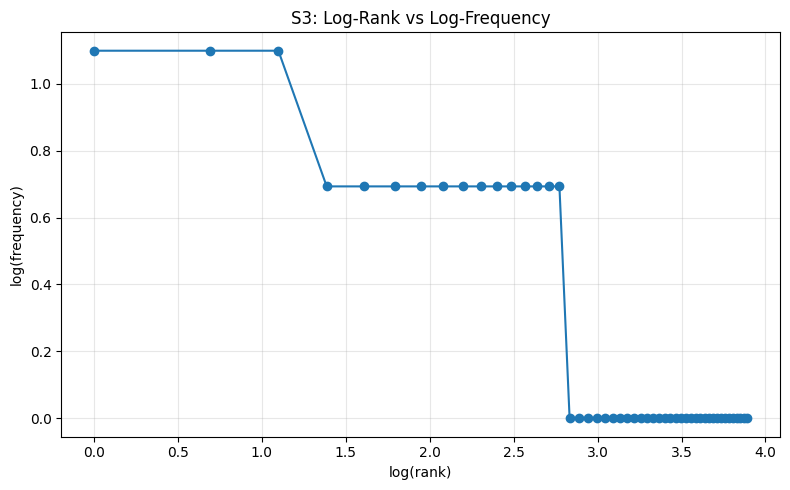


TOP 5 BIGRAMS — S1
[(('.', 'it'), 3), (('the', 'lms'), 3), (('the', 'password'), 2), (('failed', 'to'), 2), (('to', 'open'), 2)]

TOP 5 BIGRAMS — S3
[(('failed', 'open'), 2), (('keeps', 'asking'), 2), (('asking', 'login'), 2), (('please', 'resolve'), 2), (('works', 'another'), 2)]


In [10]:
# Your code
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Keep each ticket as a separate token sequence when calculating bigrams
ticket_ids = df["Ticket_ID"].tolist()

S1_sequences = [
    processed[ticket_id]["tokens"]
    for ticket_id in ticket_ids
]

S2_sequences = [
    [
        token for token in processed[ticket_id]["tokens"]
        if not is_punct(token)
    ]
    for ticket_id in ticket_ids
]

S3_sequences = [
    processed[ticket_id]["final"]
    for ticket_id in ticket_ids
]

S1 = [token for sequence in S1_sequences for token in sequence]
S2 = [token for sequence in S2_sequences for token in sequence]
S3 = [token for sequence in S3_sequences for token in sequence]

S4 = [porter.stem(token) for token in S3]


def corpus_stats(name, tokens):
    total = len(tokens)
    unique = len(set(tokens))

    return {
        "Corpus": name,
        "Total tokens": total,
        "Unique tokens": unique,
        "TTR": unique / total if total else 0.0
    }


stats_df = pd.DataFrame([
    corpus_stats("S1: All tokens", S1),
    corpus_stats("S2: Without punctuation", S2),
    corpus_stats("S3: Final tokens", S3),
    corpus_stats("S4: Porter-stemmed S3", S4)
])

print("CORPUS STATISTICS")
display(stats_df)


# Top 10 words
print("\nTOP 10 WORDS — S1")
print(Counter(S1).most_common(10))

print("\nTOP 10 WORDS — S3")
print(Counter(S3).most_common(10))


# Log(rank) versus log(frequency) plot for S3
s3_counts = Counter(S3)
ranked_words = s3_counts.most_common()

ranks = np.arange(1, len(ranked_words) + 1)
frequencies = np.array(
    [frequency for word, frequency in ranked_words]
)

plt.figure(figsize=(8, 5))
plt.plot(
    np.log(ranks),
    np.log(frequencies),
    marker="o",
    linestyle="-"
)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("S3: Log-Rank vs Log-Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Calculate bigrams inside each ticket to avoid crossing ticket boundaries
def get_bigrams(sequences):
    counts = Counter()

    for sequence in sequences:
        counts.update(zip(sequence, sequence[1:]))

    return counts


print("\nTOP 5 BIGRAMS — S1")
print(get_bigrams(S1_sequences).most_common(5))

print("\nTOP 5 BIGRAMS — S3")
print(get_bigrams(S3_sequences).most_common(5))

**Observation:** TTR increases from **0.5211 in S1** to **0.6912 in S4**. S1 includes punctuation and stopwords, while S4 uses the filtered final tokens and Porter stemming. Removing punctuation/stopwords reduces the total from 142 tokens to 68; stemming then merges some word forms, reducing the unique vocabulary from 49 in S3 to 47 in S4. Since TTR is unique tokens divided by total tokens, the overall ratio remains higher than in S1.

---
## Q6. Interpretation
Answer all four parts using the dataset and results above.

> **Written answers — Q6 (a)–(d)**
>
> **(a) Why does TTR change from S1 to S4?** TTR rises from 0.5211 to 0.6912 because S1 includes punctuation and stopwords, whereas S4 uses the final filtered tokens after Porter stemming. The total token count falls from 142 to 68, and stemming merges word forms, reducing unique tokens from 49 in S3 to 47 in S4. TTR changes with both the total and unique token counts.
>
> **(b) Example where the tokenizers differ.** `isn't` is split into `is` and `n't` by `word_tokenize()`, while `my_tokenize()` preserves `isn't` as one contraction token.
>
> **(c) One undesirable stemming result.** The selected Regexp Stemmer removes the suffix `ing` without checking the word root, so `running` becomes `runn`, which is not a valid English word. Lancaster also shortens `slowly` to `slow`, losing its adverbial form.
>
> **(d) POS-aware lemmatization example.** When `slowly` is tagged as an adverb (`RB`), WordNet lemmatization returns `slowly`, preserving the adverb form. A stemmer may instead return `slowli` (Porter) or `slow` (Lancaster), which does not preserve the original word form as well.